# 05 — Forward and temporal evaluation

**Purpose.** Inspect an alternative historical-reference audit, then summarize the saved
temporal-alignment and calibration-sensitivity results.

**Inputs** `configs/evaluation_settings.json` and
`results/paper_tables/{v6_forward_partition_audit,temporal_nulls,calibration_bootstrap,
supervised_robustness}.csv`.

**Outputs** `results/regenerated/forward_temporal_summary.csv`.

The historical-reference audit is not the fitting/calibration partition used for the primary
window-size and fusion comparisons. Those comparisons fit on the first 70% of the separate
benign recording and reuse that fitting partition for standardization and threshold calibration.
The fixed benign-reference fits are then evaluated on later campaigns without refitting.

These cells read saved summaries only. The alarm-timing and randomized-schedule implementations
are not included in this public replay package; the summaries alone do not verify their
implementation constraints. The separate benign capture has later calendar timestamps than the
attack capture, so fixed-reference results are not a demonstration of a past-only deployment.


In [1]:
import os, sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive; drive.mount('/content/drive')
    os.environ.setdefault('PROVICS_ROOT', '/content/drive/MyDrive/provics-recording-aware-evaluation')
else:
    os.environ.setdefault('PROVICS_ROOT', str(Path.cwd().parent))
sys.path.insert(0, os.environ['PROVICS_ROOT'])
from src.utils.paths import project_root
ROOT = project_root(); print('Project folder:', ROOT.name)

# Render compact, readable tables below each cell.
from IPython.display import display
import pandas as pd
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)


Project folder: code


In [2]:
import pandas as pd
from src.evaluation.replay import load_settings
settings = load_settings()
print('Primary detector reference:', settings['primary_reference'])
print('The table below audits an ALTERNATIVE historical-reference construction;')
print('its counts are not the fitting partitions behind the primary comparisons.')
audit = pd.read_csv(ROOT / settings['historical_reference_audit']['table'])
display(audit[['held_out','causal_past_campaigns','n_fit','n_cal','fit_frac',
               'labelled_in_fit','labelled_in_cal']])
print()
print('The alternative reference is action-screened but otherwise unverified: prior labeled')
print('attack windows are excluded, but persistence or recovery may remain unlabeled.')


Primary detector reference: {'recording': 'separate_benign', 'fit_fraction': 0.7, 'calibration': 'benign_fitting_partition', 'refit_between_campaigns': False}
The table below audits an ALTERNATIVE historical-reference construction;
its counts are not the fitting partitions behind the primary comparisons.


,held_out,causal_past_campaigns,n_fit,n_cal,fit_frac,labelled_in_fit,labelled_in_cal
0,C2,['C1'],278,120,0.698,0,0
1,C3,"['C1', 'C2']",358,154,0.699,0,0
2,C4,"['C1', 'C2', 'C3']",396,170,0.700,0,0



The alternative reference is action-screened but otherwise unverified: prior labeled
attack windows are excluded, but persistence or recovery may remain unlabeled.


In [3]:
# The ordering constraint, checked explicitly rather than assumed.
for row in audit.itertuples():
    cal_last = pd.Timestamp(row.cal_last); start = pd.Timestamp(row.heldout_start)
    print(f'{row.held_out}: calibration ends {cal_last}  held-out starts {start}  ok={cal_last <= start}')


C2: calibration ends 2026-04-16 17:30:00+00:00  held-out starts 2026-04-16 17:35:19.847000+00:00  ok=True
C3: calibration ends 2026-04-16 22:39:00+00:00  held-out starts 2026-04-16 22:44:50.007000+00:00  ok=True
C4: calibration ends 2026-04-17 01:59:00+00:00  held-out starts 2026-04-17 02:04:13.343000+00:00  ok=True


In [4]:
# Read the saved results of 2,000 randomized schedules. No schedule is generated here.
nulls = pd.read_csv(ROOT / 'results/paper_tables/temporal_nulls.csv')
at60 = nulls[nulls.window_s == 60].groupby(['family','null']).p_empirical.mean().unstack().round(4)
display(at60)
print('\nq_align = (1 + #{schedules at least as extreme}) / (B + 1), B = 2000.')
print('Smallest attainable value is 1/2001 ~ 0.0005.')
print('These are saved randomisation summaries, not a new significance test; they',
      'supports alignment to the attack-episode envelope rather than action-level detection.')


null,circular_shift,duration_matched
family,,
M1,0.0602,0.0267
M2,0.3889,0.3704
M3,0.3227,0.1278
M4,0.0105,0.0005
cyber_only_fusion,0.2650,0.1865
late_or,0.0071,0.0005
latent_cca,0.0504,0.0284
sum_z_fusion,0.0034,0.0005



q_align = (1 + #{schedules at least as extreme}) / (B + 1), B = 2000.
Smallest attainable value is 1/2001 ~ 0.0005.
These are saved randomisation summaries, not a new significance test; they supports alignment to the attack-episode envelope rather than action-level detection.


In [5]:
# All tested cells are reported, including those that do not clear the nulls.
everything = pd.read_csv(ROOT / 'results/paper_tables/temporal_nulls_all_cells.csv')
print('cells reported:', len(everything))
display(everything.groupby('family').p.agg(['min','max']).round(4))


cells reported: 40


,min,max
family,,
M1,0.0267,0.0602
M2,0.3704,0.3889
M3,0.1229,0.5592
M4,0.0005,0.0135
cyber_only_fusion,0.1865,0.6162
late_or,0.0005,0.0071
latent_cca,0.0284,0.0504
sum_z_fusion,0.0005,0.0135


In [6]:
# Summarize the saved calibration-bootstrap replicates; do not draw new samples.
import numpy as np
boot = pd.read_csv(ROOT / 'results/paper_tables/calibration_bootstrap.csv')
at014 = boot[boot.budget_q == 0.014]
spread = at014.groupby('family').outside_action_occupancy.agg(
    lo=lambda s: np.percentile(s, 2.5), hi=lambda s: np.percentile(s, 97.5)).round(2)
display(spread)
print('\nThe operating point moves substantially on calibration draw alone.')


,lo,hi
family,,
M1,0.06,0.06
M2,0.06,0.20
M3,0.52,0.94
M4,0.68,0.82
cyber_only_fusion,0.13,0.94
late_or,0.43,0.95
latent_cca,0.00,0.12
sum_z_fusion,0.79,0.98



The operating point moves substantially on calibration draw alone.


### Read the saved calibration-sensitivity range

Each line spans the existing 2.5th to 97.5th percentiles in the table above. This describes the saved calibration resamples, not independent campaign-level uncertainty. No new bootstrap is run.


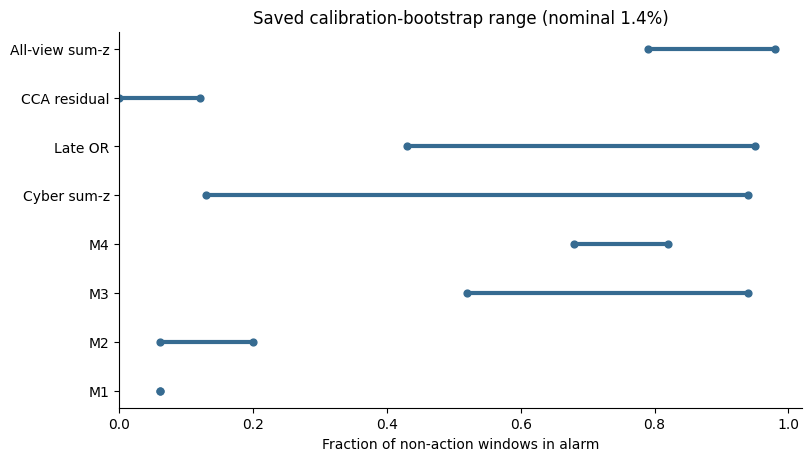

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
positions = range(len(spread))
ax.hlines(positions, spread.lo, spread.hi, color='#366b91', linewidth=3)
ax.scatter(spread.lo, positions, color='#366b91', s=24)
ax.scatter(spread.hi, positions, color='#366b91', s=24)
labels = {'sum_z_fusion': 'All-view sum-z', 'cyber_only_fusion': 'Cyber sum-z',
          'late_or': 'Late OR', 'latent_cca': 'CCA residual'}
ax.set_yticks(list(positions), [labels.get(name, name) for name in spread.index])
ax.set(xlim=(0, 1.02), xlabel='Fraction of non-action windows in alarm',
       title='Saved calibration-bootstrap range (nominal 1.4%)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()
plt.close(fig)

In [8]:
# Is the pattern specific to the Isolation Forest? A fixed supervised check says no.
supervised = pd.read_csv(ROOT / 'results/paper_tables/supervised_robustness.csv')
by_view = supervised.groupby(['modality','model']).delta_cw.mean().unstack().round(3)
display(by_view)
print('\nM1-M3 keep a positive gap across model families; M4 is more model- and campaign-dependent.')

out = ROOT / 'results/regenerated'; out.mkdir(parents=True, exist_ok=True)
at60.to_csv(out / 'forward_temporal_summary.csv')
print('\nwrote results/regenerated/forward_temporal_summary.csv')


model,logistic_regression,mlp,random_forest
modality,,,
M1,0.185,0.179,0.358
M2,0.192,0.174,0.229
M3,0.516,0.388,0.277
M4,-0.210,-0.038,0.293



M1-M3 keep a positive gap across model families; M4 is more model- and campaign-dependent.

wrote results/regenerated/forward_temporal_summary.csv


## What this notebook checked

- The alternative historical-reference audit has ordered fitting/calibration partitions and
  excludes prior labeled attack windows. It does not establish the primary detector partitions.
- Primary comparisons use fixed benign-reference fits and reuse their fitting scores for calibration.
- Saved temporal-alignment results describe alignment with labeled periods, not action-level identification.
- Calibration resampling changes alarm occupancy while model scores remain fixed.
- The supervised-model summaries describe model-family sensitivity.
